In [1]:
import numpy as np
import pymc as pm  # if using pymc >=4
import arviz as az
import matplotlib.pyplot as plt

plt.rcParams["svg.fonttype"] = "none"
import seaborn as sns

import pandas as pd

import json

from pytensor.tensor import cumsum
import pytensor.tensor as at

from glob import glob

import mvEEG.mvEEG as mvEEG

In [2]:
METRIC = "signedDprime"

In [3]:
# possible bends (SS) for each function. The last option (8) corresponds to the full model with fewest contraints on the shape of the function
# every bend is going to be compared via Savage-Dickey density ratio to a model with one fewer bend.
WM_possible_bends = [4, 6, 8]
WM_SS_to_idx = {0: 0, 2: 1, 4: 2, 6: 3, 8: 4}


prior_sds = np.arange(0.05, 0.55, 0.05)
prior_sds

array([0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ])

# Model Comparison

In [4]:
bends_flipped = WM_possible_bends[::-1]
set_sizes = bends_flipped + [2]  # add the first set size back in to make it easier to index into the BFs

PRIOR SD: 0.05


/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_s

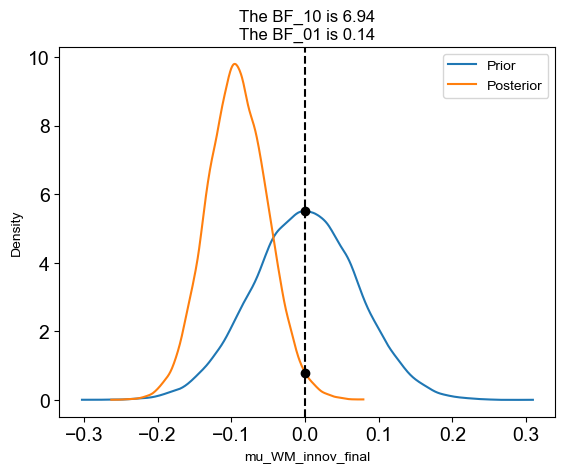

/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_s

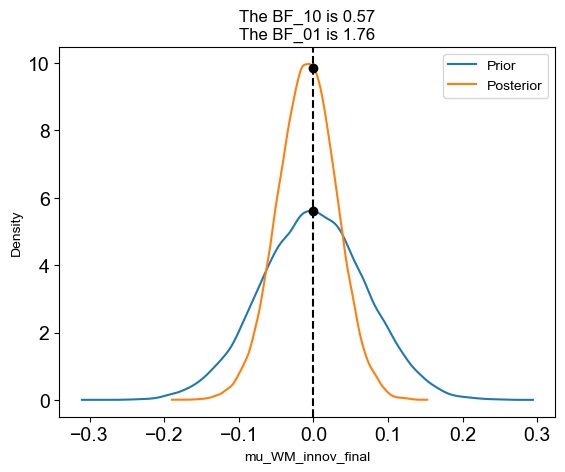

/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_s

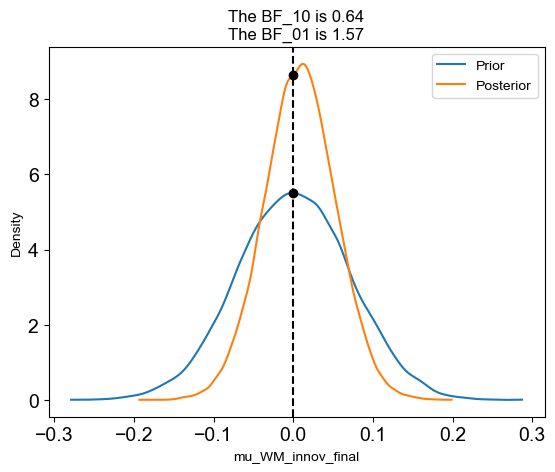

PRIOR SD: 0.1


/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_s

PRIOR SD: 0.15000000000000002


/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_s

PRIOR SD: 0.2


...

/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_s

PRIOR SD: 0.45


/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_s

PRIOR SD: 0.5


/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_s

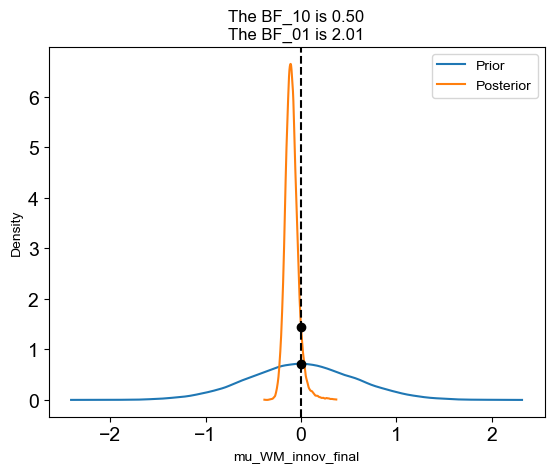

/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_s

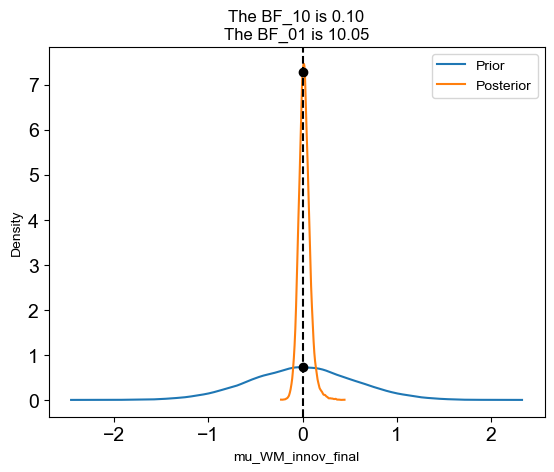

/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_s

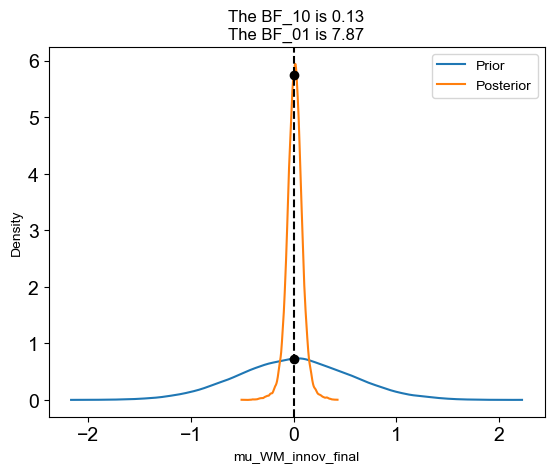

In [5]:
winning_comparisons = pd.DataFrame()
r_hat_dict = {}
ess_dict = {}
for prior_sd in prior_sds:
    print(f"PRIOR SD: {prior_sd}")
    model_files = sorted(glob(f"model_comparison/model_{METRIC}_priorSD{prior_sd*100:.0f}_WMbend*.nc"))
    all_BFs = {}
    for model_file in model_files:
        model_name = model_file.split("_")[-1].split(".")[0]
        idata = az.from_netcdf(model_file)
        summary_df = az.summary(idata)
        r_hat_dict[model_name+str(prior_sd)] = summary_df["r_hat"].describe()['min']
        ess_dict[model_name+str(prior_sd)] = summary_df.loc["mu_WM_innov_final", "ess_bulk"]
        BF_dict, _ = az.plot_bf(idata, var_name="mu_WM_innov_final", ref_val=0)
        all_BFs[model_name] = BF_dict
        # want to view the results at the most extreme priors to get a sense of the transition between them
        if prior_sd in [0.05, 0.5]:
            plt.show()
        plt.close()

    organized_BFs = {}
    for i, set_size_i in enumerate(bends_flipped):
        curr_BF = all_BFs[f"WMbend{set_size_i}"]["BF10"]
        organized_BFs[f"{set_size_i}/{set_sizes[i+1]}"] = curr_BF
        for j, set_size_j in enumerate(bends_flipped[i + 1 :]):
            curr_BF = curr_BF * all_BFs[f"WMbend{set_size_j}"]["BF10"]
            organized_BFs[f"{set_size_i}/{set_sizes[i+j+2]}"] = curr_BF

    # now flip to get the other direction (e.g., WM2 vs WM4 instead of WM4 vs WM2)
    curr_keys = list(organized_BFs.keys())
    for key in curr_keys:
        set_size_i = key.split("/")[0]
        set_size_j = key.split("/")[1]
        organized_BFs[f"{set_size_j}/{set_size_i}"] = 1 / organized_BFs[key]

    BF_df = (
        pd.DataFrame.from_dict(organized_BFs, orient="index", columns=["BF"])
        .reset_index()
        .rename(columns={"index": "Comparison (Num / Denom)"})
        .sort_values("BF", ascending=False)
    )
    # split comparison column into numerator and denominator for plotting
    BF_df[["Numerator", "Denominator"]] = BF_df["Comparison (Num / Denom)"].str.split("/", expand=True).astype(int)

    # find the winning set size, build up its dataframe
    for ss in set_sizes:
        ss_bf_df = BF_df.query("Numerator == @ss")
        if np.all(ss_bf_df["BF"] > 1):
            winning_ss = ss
            winning_ss_bf_df = pd.concat(
                [
                    ss_bf_df,
                    pd.DataFrame(
                        {
                            "Comparison (Num / Denom)": f"{winning_ss}/{winning_ss}",
                            "BF": 1,
                            "Numerator": winning_ss,
                            "Denominator": winning_ss,
                        },
                        index=[0],
                    ),
                ],
                ignore_index=True,
            )
            winning_ss_bf_df["logBF"] = np.log(1 / winning_ss_bf_df["BF"])
            winning_ss_bf_df["log10BF"] = np.log10(1 / winning_ss_bf_df["BF"])
            winning_ss_bf_df["prior_sd"] = prior_sd
            winning_comparisons = pd.concat([winning_comparisons, winning_ss_bf_df], ignore_index=True)

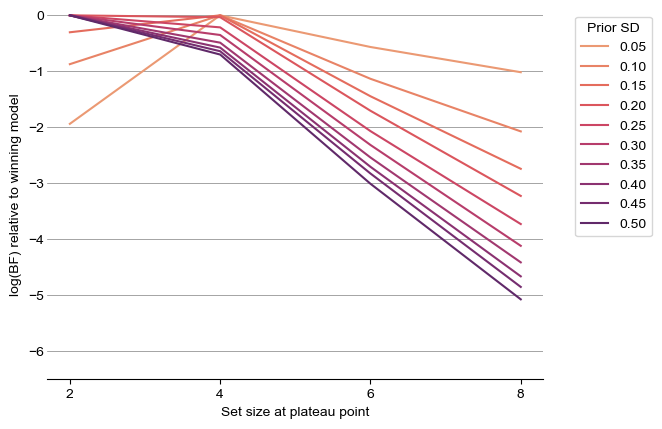

In [6]:
pal = sns.color_palette("flare", n_colors=len(prior_sds))
for i, prior_sd in enumerate(prior_sds):
    subset = winning_comparisons.query("prior_sd == @prior_sd")
    _ = sns.lineplot(data=subset, x="Denominator", y="logBF", color=pal[i], label=f"{prior_sd:.2f}")

# in the legend, add a line for each prior sd with the corresponding color


plt.legend(title="Prior SD", bbox_to_anchor=(1.05, 1), loc="upper left")
sns.despine()
# add lines at each log integer (0, -1, to -6)
for i in range(0, -7, -1):
    plt.axhline(i, color="gray", linestyle="-", linewidth=0.5, zorder=-1)

# remove the y axis lines, but keep the labels
plt.gca().spines["left"].set_visible(False)
# remove the yaxis ticks but keep the labels
plt.gca().yaxis.set_ticks_position("none")
# shift the ylabels a bit to the right
plt.gca().yaxis.set_tick_params(pad=-1)
plt.xticks([2, 4, 6, 8])
plt.ylim(-6.5, 0.1)

plt.ylabel("log(BF) relative to winning model")
_ = plt.xlabel("Set size at plateau point")
plt.savefig(f"figures/model_comparison_winning_models_{METRIC}.png", bbox_inches="tight", dpi=300)

In [7]:
winning_comparisons.query("logBF==0")

,Comparison (Num / Denom),BF,Numerator,Denominator,logBF,log10BF,prior_sd
3,4/4,1.0,4,4,0.0,0.0,0.05
7,4/4,1.0,4,4,0.0,0.0,0.10
11,4/4,1.0,4,4,0.0,0.0,0.15
15,2/2,1.0,2,2,0.0,0.0,0.20
19,2/2,1.0,2,2,0.0,0.0,0.25
23,2/2,1.0,2,2,0.0,0.0,0.30
27,2/2,1.0,2,2,0.0,0.0,0.35
31,2/2,1.0,2,2,0.0,0.0,0.40
35,2/2,1.0,2,2,0.0,0.0,0.45
39,2/2,1.0,2,2,0.0,0.0,0.50


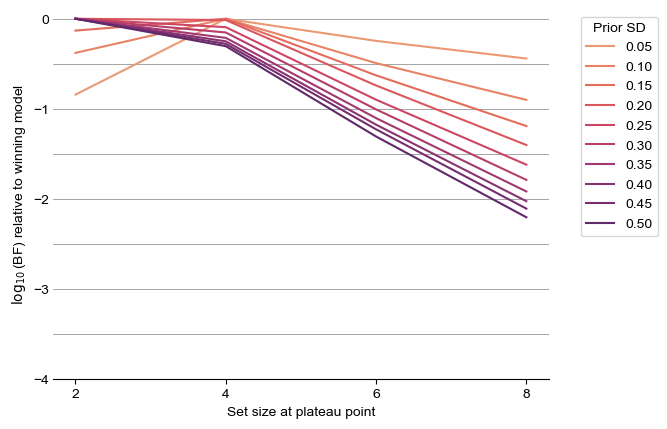

In [8]:
pal = sns.color_palette("flare", n_colors=len(prior_sds))
for i, prior_sd in enumerate(prior_sds):
    subset = winning_comparisons.query("prior_sd == @prior_sd")
    _ = sns.lineplot(data=subset, x="Denominator", y="log10BF", color=pal[i], label=f"{prior_sd:.2f}")

# in the legend, add a line for each prior sd with the corresponding color


plt.legend(title="Prior SD", bbox_to_anchor=(1.05, 1), loc="upper left")
sns.despine()
for i in range(0, -8, -1):
    plt.axhline(i/2, color="gray", linestyle="-", linewidth=0.5, zorder=-1)

# remove the y axis lines, but keep the labels
plt.gca().spines["left"].set_visible(False)
# remove the yaxis ticks but keep the labels
plt.gca().yaxis.set_ticks_position("none")
# shift the ylabels a bit to the right
plt.gca().yaxis.set_tick_params(pad=-1)
plt.xticks([2, 4, 6, 8])
plt.ylim(-4, 0.1)
plt.yticks([-4, -3, -2, -1, 0])

plt.ylabel(r"$\log_{10}$(BF) relative to winning model")
_ = plt.xlabel("Set size at plateau point")
plt.savefig(f"figures/model_comparison_winning_models_{METRIC}_log10.png", bbox_inches="tight", dpi=300)

# examining model convergence details

In [9]:
r_hat_df = pd.DataFrame.from_dict(r_hat_dict, orient="index", columns=["r_hat"])
r_hat_df.describe()

,r_hat
count,30.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0


In [10]:
ess_df = pd.DataFrame.from_dict(ess_dict, orient="index", columns=["ess"])
ess_df.describe()

,ess
count,30.000000
mean,28757.333333
std,15443.859792
min,4801.000000
25%,18885.500000
50%,26859.000000
75%,31988.750000
max,70651.000000
